# CsI–SiPM：保持平均谱的成分方差模型与原生检验

2026-11-02。承接[完整母事件池选择核查](codex_0001_csi_full_pool_selection.ipynb)：原队列截断并没有消除F202过宽，且全局事件方差CV置零会使Co的F50过窄。本轮实现一个最小的新读出模型：让互补成分的事件方差分别变化，保留平均噪声协方差、平均响应和原Geant4雪崩历史。

实现位于`simulation/include/SpectralVarianceSplit.hh`与`simulation/src/SpectralVarianceSplit.cc`，经已有`SignalDependentNoise`进入`csi_sources`和原生重放程序。Python只负责矩预测、校准、提取和统计，最终比较波形由C++读出生成。新选项默认关闭，旧配置不增加新随机流。

现有256000个母事件全部参与当前选择：Co64000、Am192000。原响应r0与零CV r0共512000条控制读出必须与上一轮ADC逐样点相同；候选r0/r1共512000条读出用于检查。**新增独立Geant4输运及实验事件均为0**。旧实验段和MC已参与探索，不能称为盲验证。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/spectral_split_20261102'
def read(path):return json.loads(Path(path).read_text())
def fmt(x):return '不可估计' if x is None else f'{x:.4g}'
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(v) for v in x['CI95'])+f"] ({x['valid_draws']}/512)"
def table(head,rows):return '\n'.join(['|'+'|'.join(head)+'|','|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'protocol.json');fit=read(OUT/'fit.json');a=read(OUT/'analysis.json');d=read(OUT/'decision.json')
display(Markdown('**本轮结论：**'+d['conclusion_zh']))
for finding in d['findings_zh']:display(Markdown(finding))

**本轮结论：**已实现并完成保持平均谱的分成分方差候选原生检查。候选尚未在两个源、两条读出中同时通过联合门槛，不能宣布PID与波动全面一致或替换默认配置。

Co60，r0：F50/F102/F202 SD比由0.975/1.158/1.235变为1.073/0.994/1.045；F202条件95%范围[0.995, 1.122]。当前支持2170个母事件，均ADC相对L2为0.0298。

Co60，r0联合门槛：通过预定数值门槛；仍需新输运验证。

Co60，r1：F50/F102/F202 SD比由0.956/1.187/1.245变为0.940/0.951/1.041；F202条件95%范围[0.990, 1.121]。当前支持2173个母事件，均ADC相对L2为0.0299。

Co60，r1联合门槛：通过预定数值门槛；仍需新输运验证。

Am241，r0：F50/F102/F202 SD比由0.938/1.050/1.188变为0.961/1.027/1.162；F202条件95%范围[1.087, 1.268]。当前支持1399个母事件，均ADC相对L2为0.0165。

Am241，r0联合门槛：未通过，失败项：F202_SD_ratio。

Am241，r1：F50/F102/F202 SD比由0.967/1.127/1.215变为0.965/1.069/1.176；F202条件95%范围[1.103, 1.285]。当前支持1411个母事件，均ADC相对L2为0.0142。

Am241，r1联合门槛：未通过，失败项：F202_SD_ratio。

## 1. 互补成分：保持平均谱，改变事件间高阶起伏

设原有独立标准高斯创新为$w_j$，另外生成与其独立的$v_j$。对预定整数延迟$d$，定义

\[
H_j=\frac{-w_{j-d}+2w_j-w_{j+d}-v_{j-d}+v_{j+d}}4,
\qquad L_j=w_j-H_j.
\]

对所有时滞，$L$与$H$的互协方差为0，且它们联合高斯，因此相互独立。其谱为

\[
P_H(\omega)=\sin^2(\omega d/2),\quad P_L(\omega)=\cos^2(\omega d/2),\quad P_H+P_L=1.
\]

新创新为$L+\sqrt{M_H}H$，其中$M_H$是独立、正、均值为1的对数正态方差乘子。随后使用原来的FIR、无噪声信号包络$\sqrt{v\max(\mu_i,0)}$，以及均值为1的全局方差乘子$M_C$。由于$E[M_H]=E[M_C]=1$，原有二阶协方差和平均谱保留，但事件间方差及四阶矩可以变化。

**差分成分有频率旁瓣，不是互不重叠的物理高频带。** CV也不是实测SiPM增益或光产额波动。未按事件强制固定总功率，未减去每个事件的噪声均值，也未对生成ADC做幅度缩放或注入实测脉冲。边缘使用独立随机延拓，没有周期回绕。

当新增CV为0时，新函数直接返回原创新，保持原随机数和ADC精确不变。新增边缘、辅助创新及方差状态分别使用独立种子域，不消耗输运或雪崩随机数。


{'exact_complementary_operator_covariance': True,
 'mixture_trials': 40000,
 'joint_quadratic_covariance_relative_error': 0.011295934806484583,
 'observed_cov': [[0.15388349473092533,
   0.14682356718711345,
   0.16362619728145303],
  [0.14682356718711345, 0.19221265389395614, 0.20619924115596247],
  [0.16362619728145303, 0.20619924115596247, 0.24317667560487854]],
 'expected_cov': [[0.15216465273379304,
   0.14576849445937923,
   0.161903862486155],
  [0.14576849445937923, 0.19095890062158802, 0.20451450696832618],
  [0.16190386248615501, 0.20451450696832618, 0.24127901052070388]],
 'code_sha256': '16dcc4812ccc4a8368fdbdbc55ba5884491552aedc4ceae50b7033c28c885db0',
 'fixed_mean_spectrum_test': True}

{'build_directory': 'simulation/build/spectral_split_20261102',
 'csi_sources_sha256': 'f918297113d6407aab4061c0bc14b92ebfac48457fc1f102dc6d48b7e38c7ca5',
 'replay_spectral_pool_sha256': 'e9729c34a97d7a4f4b1bd908c58240359a2e9e223ebacc3f0cb43fe4777d6ac4',
 'ctest_passed': 7,
 'ctest_failed': 0,
 'ctest_selection': '-E csi_application_workflow',
 'ctest_log_sha256': '3d77f8e976aca06bd219a05fa936a4451585ed840ad3c0454b01ef1631889c75',
 'math_tests_sha256': '28fe39940946af21a6c1493a03ffa0837206f017dcba7e3ac0e8974785813fa9',
 'new_model_disabled_by_default': True}

|源|评价折|延迟/样点|延迟/ns|全局方差CV|差分方差CV|校准实测数|评价实测数|
|---|---|---|---|---|---|---|---|
|Co60|0|4|8|5.726e-08|0.4763|395|426|
|Co60|1|1|2|2.083e-09|1.911|426|395|
|Am241|0|1|2|0|0.3959|214|193|
|Am241|1|1|2|9.352e-12|0.6617|193|214|

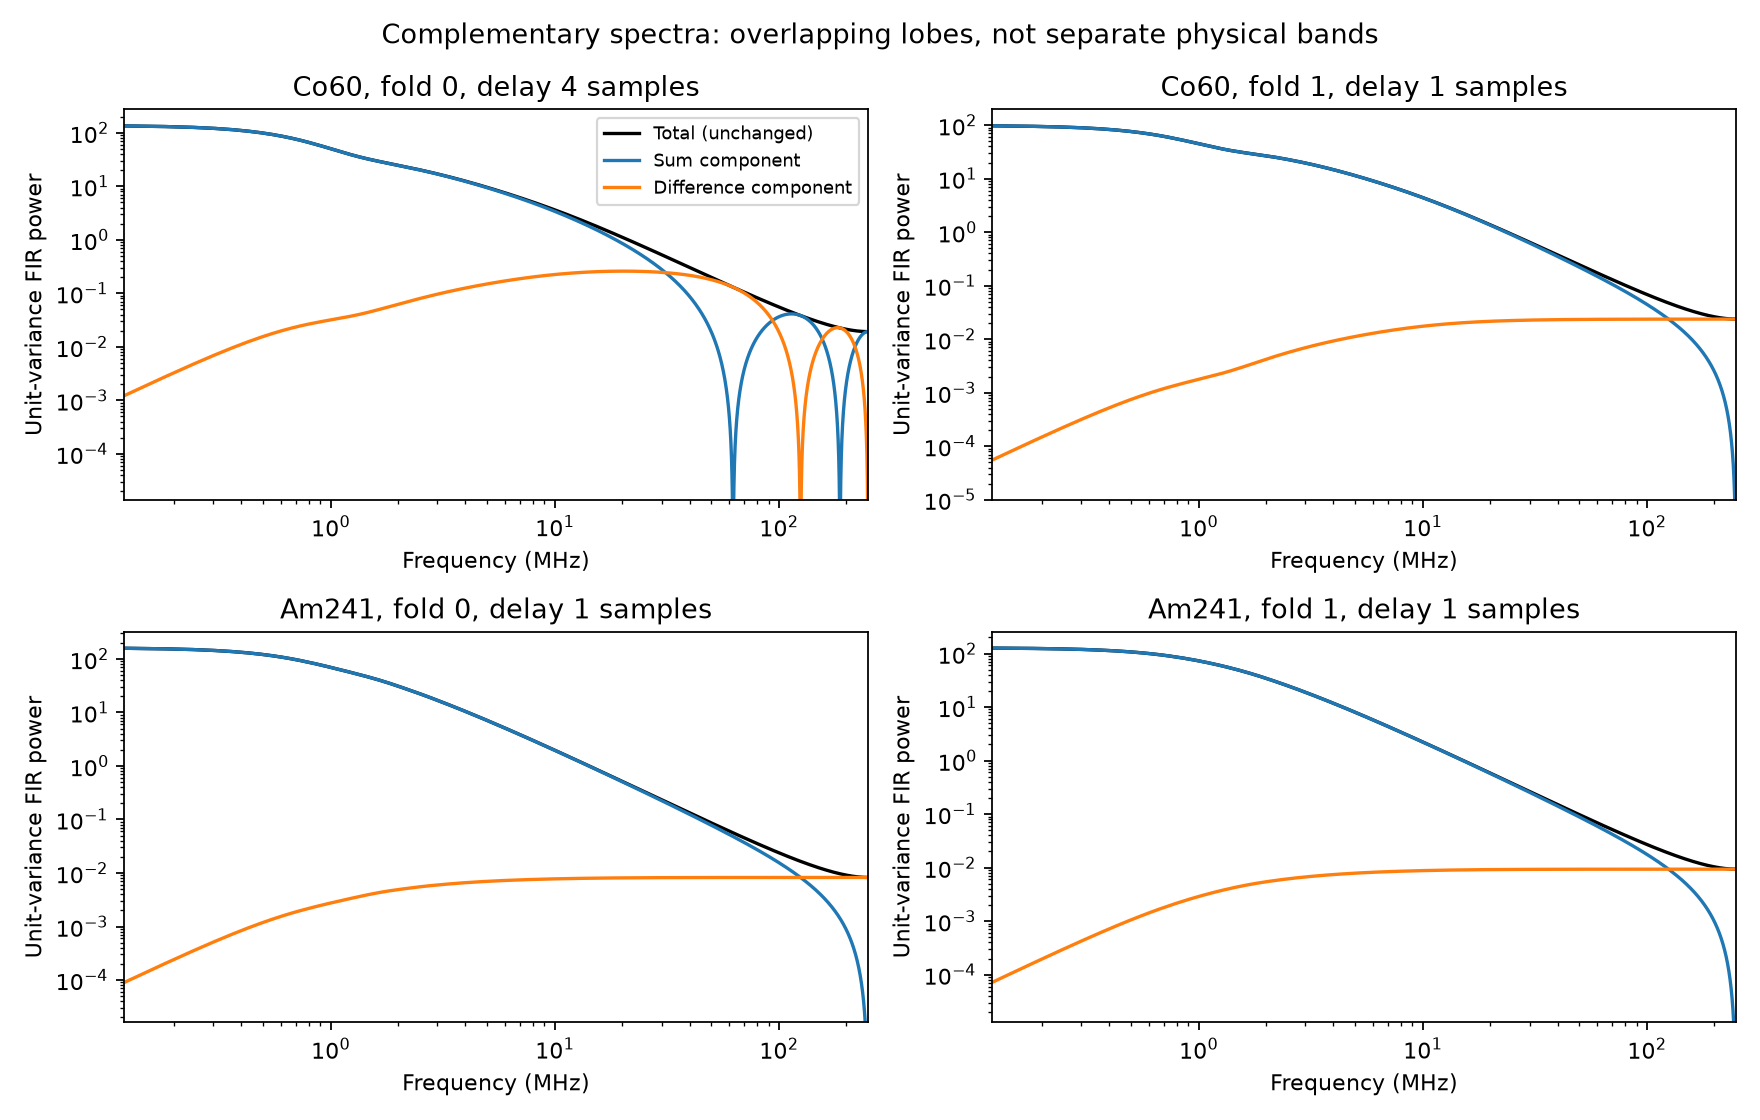

In [2]:
display(read(OUT/'algebra_tests.json'))
display(read(OUT/'build_tests.json'))
rows=[]
for source,g in fit.items():
    for ef,r in g['folds'].items():
        c=r['candidates'][r['chosen_index']]
        rows.append([source,ef,c['delay_samples'],2*c['delay_samples'],fmt(c['common_variance_cv']),fmt(c['high_variance_cv']),len(r['training_data_ids']),len(r['evaluation_data_ids'])])
display(Markdown(table(['源','评价折','延迟/样点','延迟/ns','全局方差CV','差分方差CV','校准实测数','评价实测数'],rows)))
display(Image(filename=str(OUT/'figures/spectral_partition.png')))

## 2. 先冻结矩预测和边界，再选候选

主要条件仍为last20、块128。每个评价折仅用另一折的实测F50/F102/F202完整协方差确定新增参数。原MC队列上16次零CV读出先分别计算箱内加权协方差，再平均，作为$C_0$。原半Q箱目标及所有支持箱保留。

在原零CV r0锚点和无噪声脉冲均值分母下，令$Q_i$表示某一Gaussian噪声成分独自产生的三个方差统计。用16组独立创新计算

\[
G=\frac1{N_Q}\sum_q\sum_{i\in q}w_i(1-w_i)\,E[Q_iQ_i^T].
\]

$w_i(1-w_i)$对应有限母事件加权方差的期望，保留加权均值估计的扣除项。对全谱及差分成分分别得到$G_{all},G_H$，从而预测

\[
C(F)\simeq C_0+aG_{all}+bG_H,\qquad
a=CV_C^2,\quad b=(1+a)CV_H^2.
\]

预先固定延迟为1、4、16样点，$0\le a\le CV_{原}^2$、$0\le b\le4$。以实测SD乘积规范化六个上三角协方差残差，做有界最小二乘；保留所有候选，最小目标选择延迟。未根据新原生结果扩展边界、重新选择或重新拟合。前8/后8组创新的矩预测作为敏感性记录，不当成独立母事件。

这些矩预测固定队列、锚点和分母，忽略新读出引起的定位、随机归一化、Q与质量重选，**不能代替原生ADC结果**。所有$G$的对角线非负，所以在该近似中增加非负CV无法把方差降到$C_0$以下；若零CV下限已偏宽，必须如实保留这一限制。


|源|评价折|延迟/样点|选中|协方差目标|预测F50比|预测F102比|预测F202比|
|---|---|---|---|---|---|---|---|
|Co60|0|1|False|0.03748|1.021|0.9808|1.081|
|Co60|0|4|True|0.0373|1.011|0.991|1.084|
|Co60|0|16|False|0.2405|0.8159|1.063|1.121|
|Co60|1|1|True|0.05715|0.9965|0.9759|1.1|
|Co60|1|4|False|0.06326|0.9824|0.9868|1.105|
|Co60|1|16|False|0.3658|0.7507|1.046|1.143|
|Am241|0|1|True|0.1151|0.984|1.027|1.147|
|Am241|0|4|False|0.116|0.9808|1.027|1.147|
|Am241|0|16|False|0.1228|0.9438|1.019|1.145|
|Am241|1|1|True|0.3035|0.9707|1.062|1.227|
|Am241|1|4|False|0.3078|0.9637|1.063|1.228|
|Am241|1|16|False|0.3477|0.8757|1.043|1.224|

|源|评价折|零CV F50下限|零CV F102下限|零CV F202下限|
|---|---|---|---|---|
|Co60|0|0.6554|0.8405|1.044|
|Co60|1|0.5855|0.7973|1.047|
|Am241|0|0.9438|1.019|1.145|
|Am241|1|0.8734|1.041|1.223|

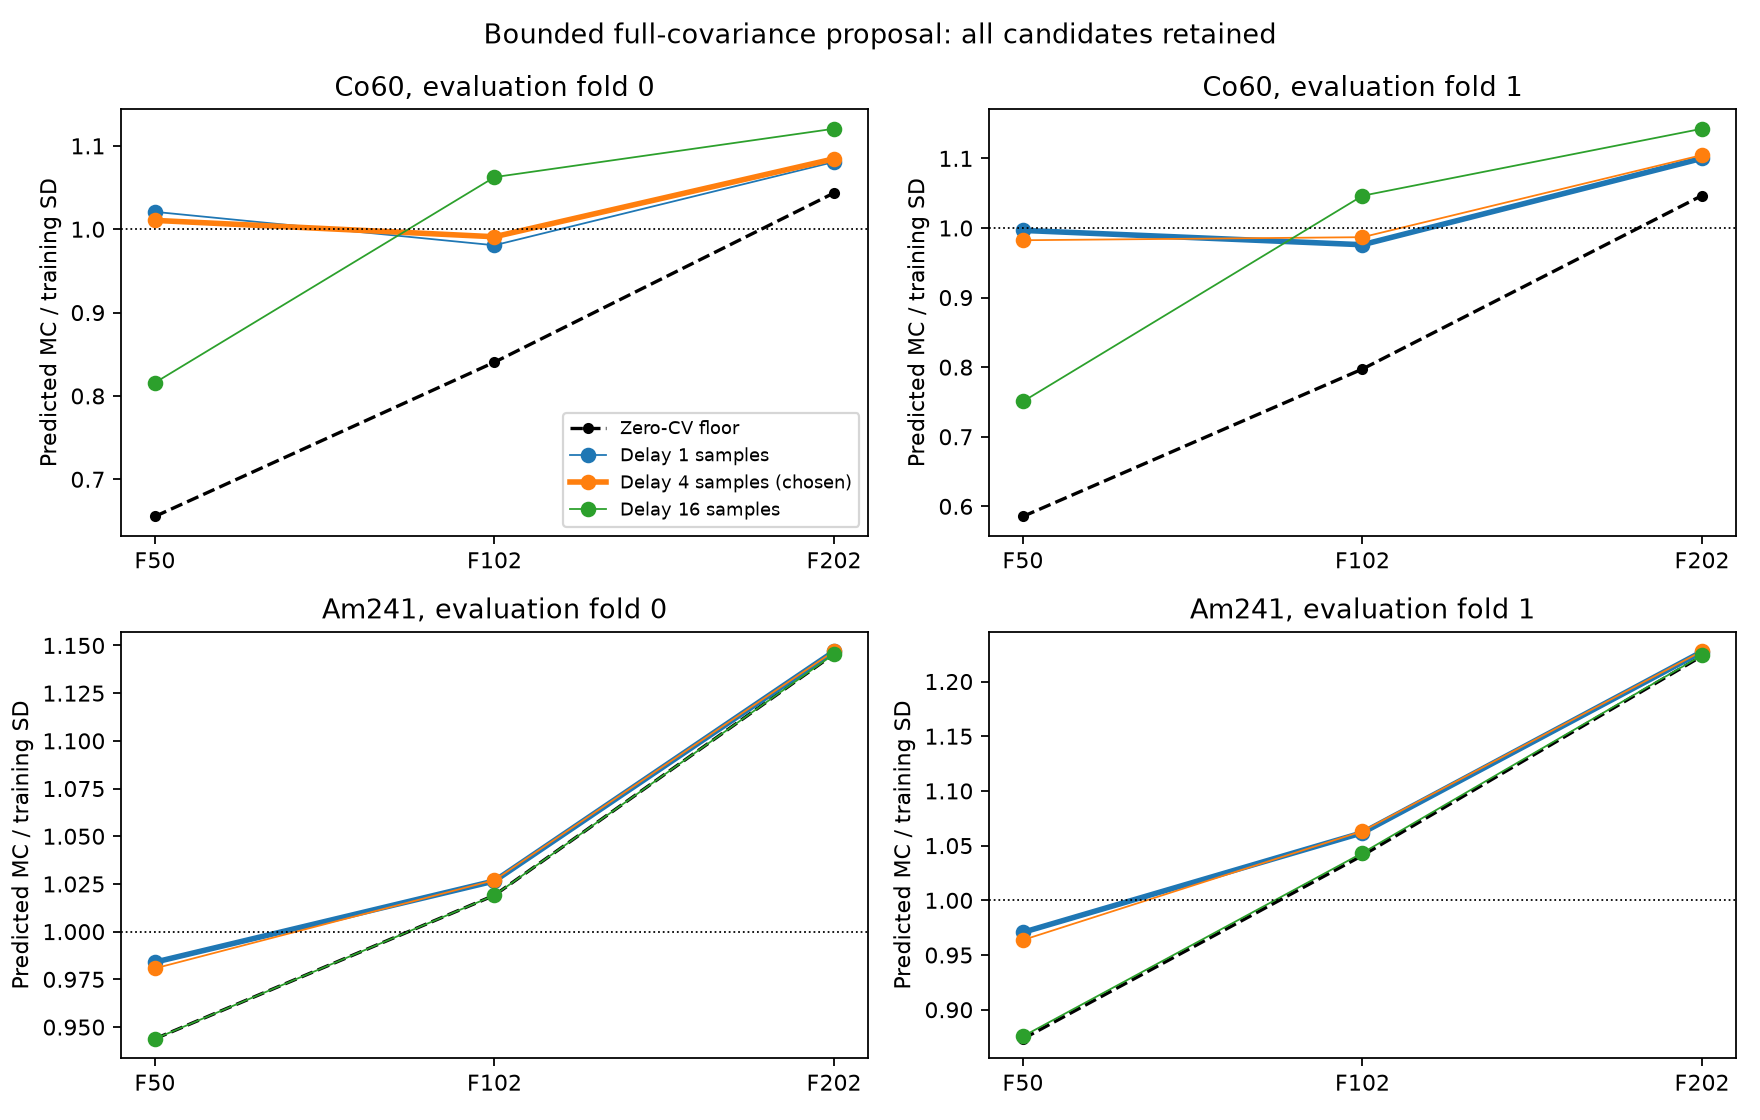

In [3]:
rows=[]
for source,g in fit.items():
    for ef,r in g['folds'].items():
        for i,c in enumerate(r['candidates']):
            rows.append([source,ef,c['delay_samples'],i==r['chosen_index'],fmt(c['objective']),*[fmt(x) for x in c['predicted_SD_ratio']]])
display(Markdown(table(['源','评价折','延迟/样点','选中','协方差目标','预测F50比','预测F102比','预测F202比'],rows)))
rows=[]
for source,g in fit.items():
    for ef,r in g['folds'].items():rows.append([source,ef,*[fmt(x) for x in r['zero_CV_SD_floor']]])
display(Markdown(table(['源','评价折','零CV F50下限','零CV F102下限','零CV F202下限'],rows)))
display(Image(filename=str(OUT/'figures/spectral_proposal.png')))

## 3. 完整母事件池的实际读出结果

`replay_spectral_pool.cc`遍历全部原母事件，不按旧Q、能量或真值预筛选。平均响应、电子噪声、光学和SiPM雪崩参数固定，只应用本轮冻结的信号噪声方差候选。原参数两个r0控制与上一轮完整池的ADC逐点比较，任何差异都会使程序失败。

候选按实际ADC重新定位并应用原全批次质量参考、幅度≥200、t10≥384和完整积分门要求，再按当前Q进入原源支持范围。Co支持6箱，Am支持3箱，半箱质量目标和PCA不变。所有使用的Q箱必须有足够事件，不能挑选表现好的箱或删除尾部。

实验仍用原512组连续块计数；此前已扩充的MC母事件计数逐项保留，新进入母事件用剩余类别的条件多项分布继续补入。同一母事件的模型与重复读出始终一起抽样。原当前/零CV控制的全部512组统计继续闭合上一轮。r0与r1分别报告，两个流不能作为已收敛的噪声平均。


|源|模型/读出|支持母事件|比当前移入|比当前移出|F50 SD比|F102 SD比|F202 SD比|F202条件95%范围|
|---|---|---|---|---|---|---|---|---|
|Co60|current_r0|2172|0|0|0.9748|1.158|1.235|[1.171, 1.33] (512/512)|
|Co60|zero_cv_r0|2170|2|4|0.637|0.8222|1.001|[0.9499, 1.072] (512/512)|
|Co60|split_r0|2170|2|4|1.073|0.994|1.045|[0.9947, 1.122] (512/512)|
|Co60|current_r1|2176|0|0|0.9563|1.187|1.245|[1.186, 1.341] (512/512)|
|Co60|zero_cv_r1|2173|3|6|0.6301|0.8358|1.01|[0.9592, 1.084] (512/512)|
|Co60|split_r1|2173|3|6|0.9401|0.9509|1.041|[0.9898, 1.121] (512/512)|
|Am241|current_r0|1399|0|0|0.9384|1.05|1.188|[1.11, 1.298] (512/512)|
|Am241|zero_cv_r0|1399|0|0|0.8914|1.015|1.162|[1.086, 1.27] (512/512)|
|Am241|split_r0|1399|0|0|0.9611|1.027|1.162|[1.087, 1.268] (512/512)|
|Am241|current_r1|1412|0|0|0.967|1.127|1.215|[1.135, 1.322] (512/512)|
|Am241|zero_cv_r1|1412|2|2|0.8978|1.067|1.18|[1.104, 1.292] (512/512)|
|Am241|split_r1|1411|2|3|0.9646|1.069|1.176|[1.103, 1.285] (512/512)|

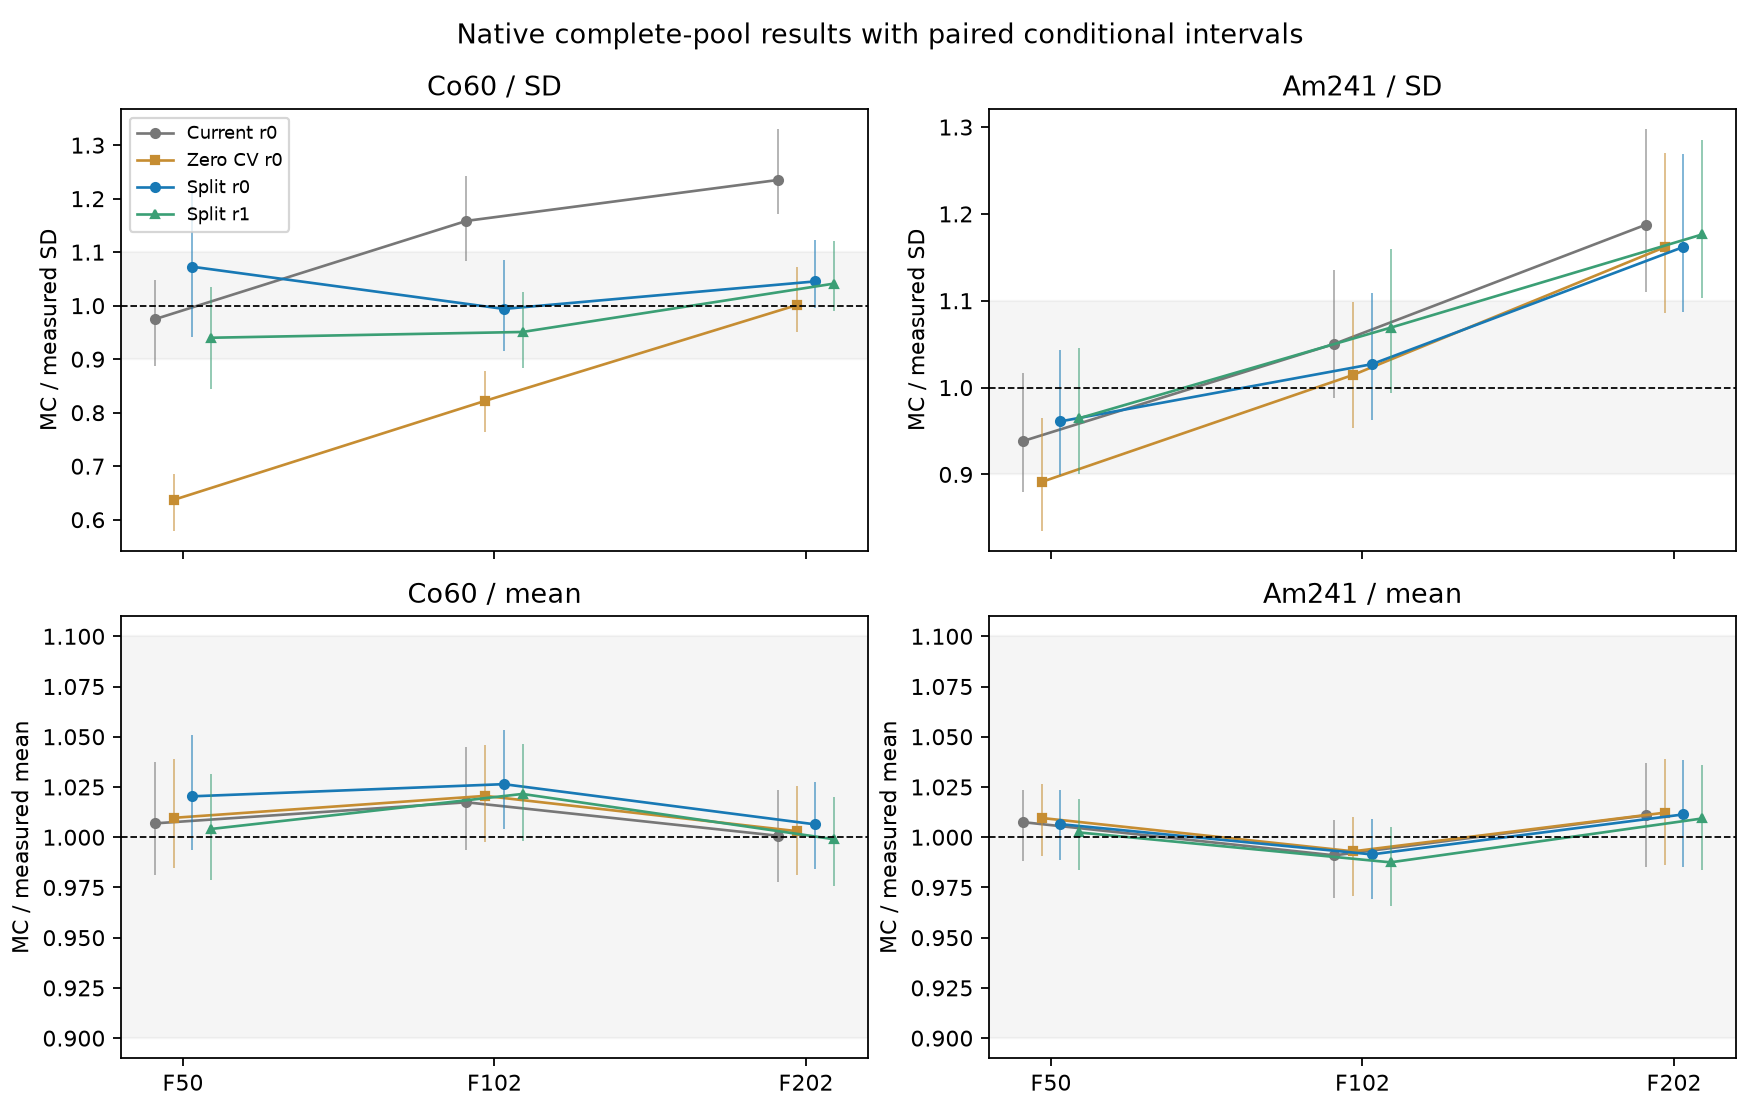

|源|读出|F50配对变化范围|F102配对变化范围|F202配对变化范围|
|---|---|---|---|---|
|Co60|0|[0.004092, 0.2053] (512/512)|[-0.2212, -0.1105] (512/512)|[-0.2288, -0.1549] (512/512)|
|Co60|1|[-0.08314, 0.04952] (512/512)|[-0.2933, -0.1857] (512/512)|[-0.2485, -0.1682] (512/512)|
|Am241|0|[-0.004133, 0.04687] (512/512)|[-0.04483, -0.00448] (512/512)|[-0.04324, -0.01078] (512/512)|
|Am241|1|[-0.02917, 0.02421] (512/512)|[-0.07841, -0.03914] (512/512)|[-0.05725, -0.02087] (512/512)|

In [4]:
rows=[]
for source,g in a.items():
    for v,r in g['variants'].items():
        count=sum(x['supported'] for x in g['selection'][v]);enter=sum(x['enter_vs_current'] for x in g['selection'][v]);leave=sum(x['leave_vs_current'] for x in g['selection'][v])
        rows.append([source,v,count,enter,leave,*[fmt(r['point'][f'F{s}_SD_ratio']) for s in [50,102,202]],ci(r['CI95']['F202_SD_ratio'])])
display(Markdown(table(['源','模型/读出','支持母事件','比当前移入','比当前移出','F50 SD比','F102 SD比','F202 SD比','F202条件95%范围'],rows)))
display(Image(filename=str(OUT/'figures/spectral_native_scales.png')))
rows=[]
for source,g in a.items():
    for r in [0,1]:
        x=g['variants'][f'split_r{r}']['change_vs_current'];rows.append([source,r,*[ci(x['CI95'][f'F{s}_SD_ratio']) for s in [50,102,202]]])
display(Markdown(table(['源','读出','F50配对变化范围','F102配对变化范围','F202配对变化范围'],rows)))

## 4. 联合检查，而不只追求F202变窄

预先设定的数值检查包括：F三尺度的均值与SD比在0.9–1.1，三个PID的SD比在0.9–1.1、中心50%/95%宽度比在0.85–1.15；平均ADC相对L2不得比同一读出原响应恶化超过0.002，PID规范化协方差误差不得恶化超过0.02，并要求F完整协方差误差改善。两个预定读出都报告。它们是候选筛查阈值，不是统计显著性检验或自动替换默认参数的依据。

平均ADC保持绝对幅度，曲线横坐标为整数对齐锚点；统计变化可来自随机实现与当前选择。F202是波形波动指标，不等同于所有PID宽度。各折自己的实测评价结果保存在`fold_checks`中，不能只依赖跨折汇总。

本轮Co在两个流的汇总门槛中通过，但分折F50点估计仍在0.869–1.148之间波动；因此汇总通过不等于每折稳定或已经证明等效。Am两个流均因F202 SD未通过，仍保留约16%–18%的长尺度过宽。


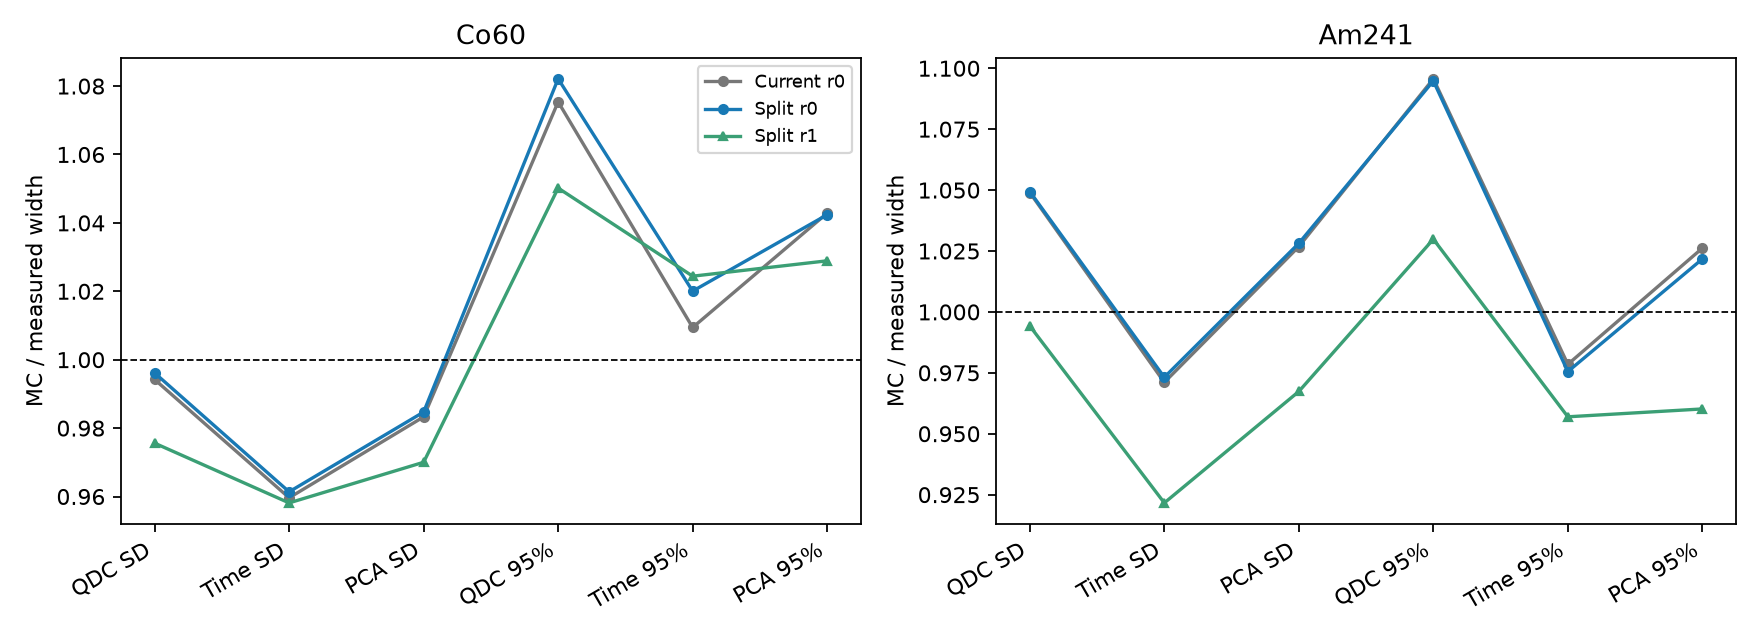

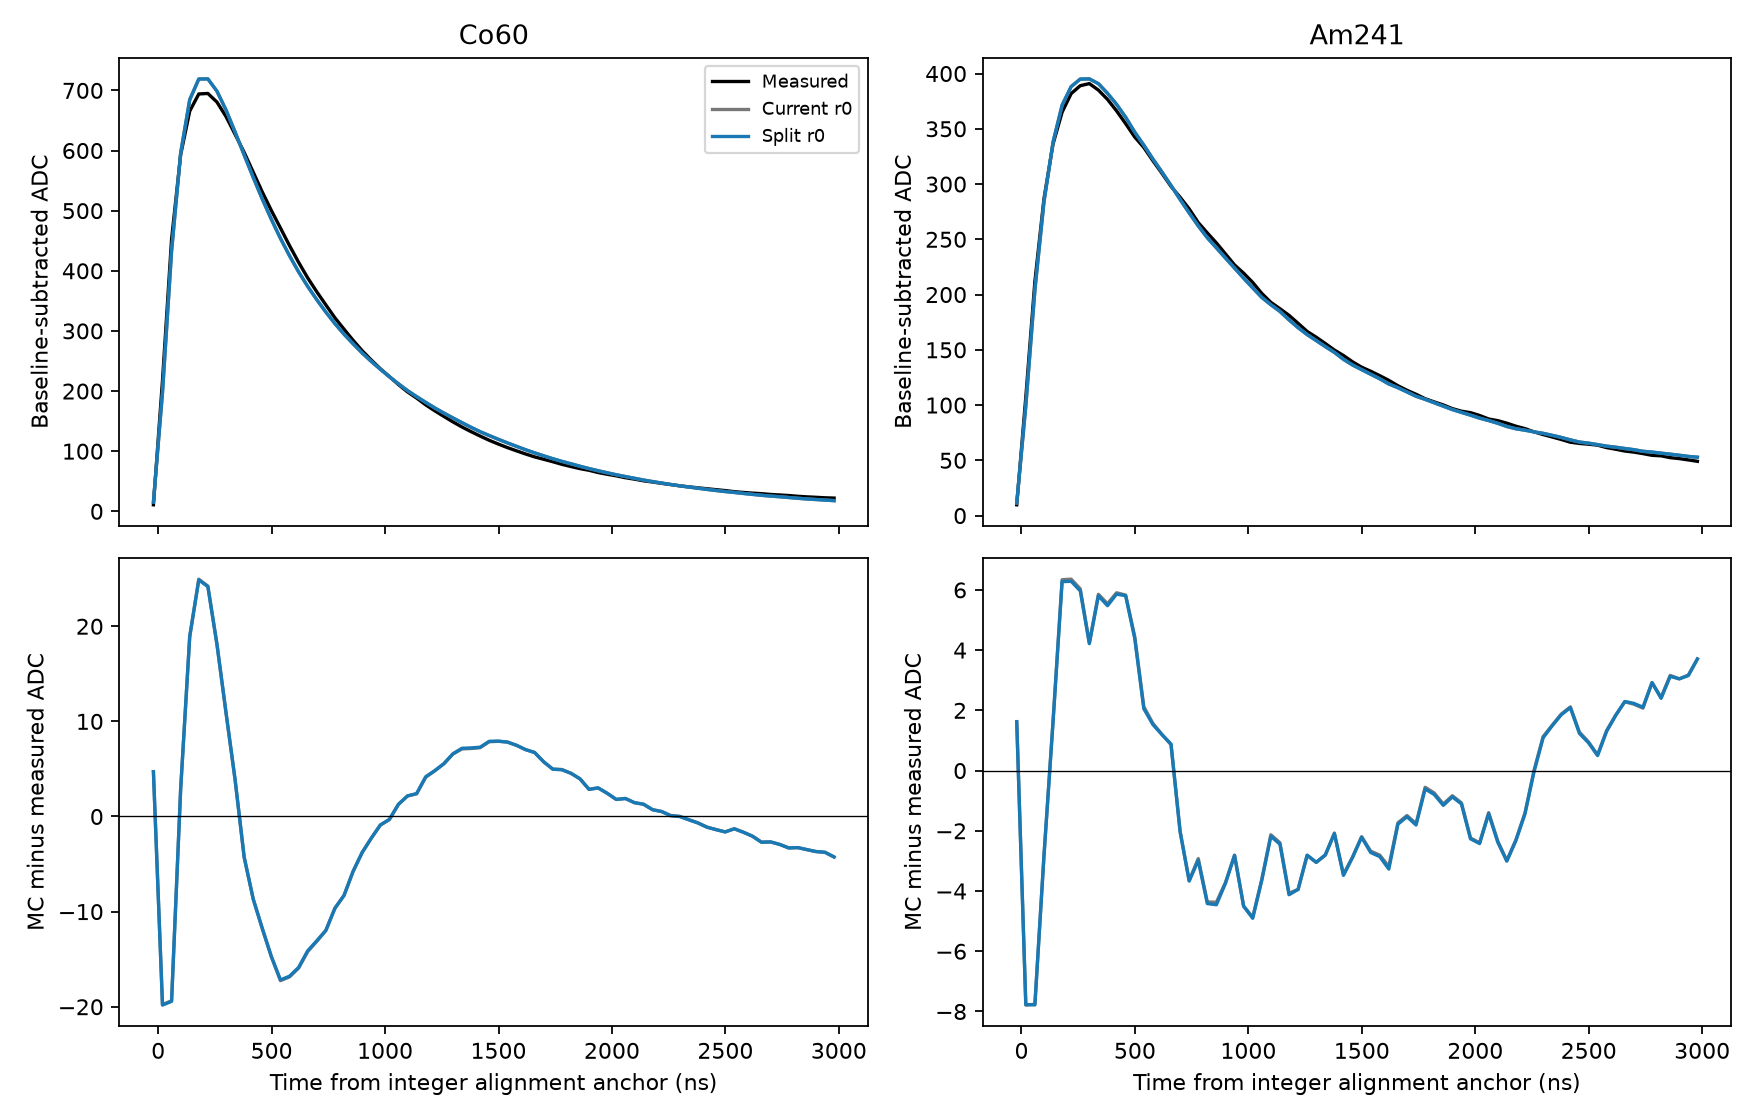

|源|读出|均ADC L2|PID协方差误差|F协方差误差|联合门槛通过|未通过项|
|---|---|---|---|---|---|---|
|Co60|0|0.02982|0.03528|0.05937|True|无|
|Co60|1|0.02994|0.05643|0.09792|True|无|
|Am241|0|0.01654|0.05679|0.1325|False|F202_SD_ratio|
|Am241|1|0.01422|0.09982|0.1593|False|F202_SD_ratio|

|源|评价折|候选|F50比|F102比|F202比|
|---|---|---|---|---|---|
|Co60|0|split_r0|0.9569|0.963|1.071|
|Co60|0|split_r1|0.8687|0.9084|1.076|
|Co60|1|split_r0|1.148|1.017|1.059|
|Co60|1|split_r1|0.9668|0.9822|1.049|
|Am241|0|split_r0|0.9265|1.072|1.236|
|Am241|0|split_r1|0.8753|1.072|1.2|
|Am241|1|split_r0|1.006|0.9797|1.106|
|Am241|1|split_r1|1.049|1.045|1.16|

边界：校准仅使用对折实测，但这些实验段和MC均已参与探索，不是新的盲验证。

边界：矩预测固定原母事件队列、零CV r0锚点和无噪声分母；自身定位、随机分母与重新选择的影响只能由实际原生ADC检查。

边界：差分成分具有频率旁瓣，不能称为独立的物理频带；方差CV描述经验状态，不是实测SiPM增益参数。

边界：本轮保持平均谱。固定分母近似下增加任何非负成分CV都不能将预测方差压到零CV下限以下；原生结果可以因选择和估计量非线性偏离该预测。

边界：仅两条预定读出流，不能视为噪声平均已经收敛。512组区间固定拟合和已实现噪声，不含重拟合、系统误差或新噪声积分。

边界：Am含alpha及gamma/电子成分，MC真值标签不提供实验事件真值；不更新实验ROC或硬件触发效率。

**下一步：**保留本轮全部候选和失败项。对仍高于实测的零CV宽度下限，检验平均谱形状、有限时间相关结构及状态混合，而不是继续只增大成分CV；同时保留已得到的短尺度改善和原生均ADC/PID约束。

In [5]:
display(Image(filename=str(OUT/'figures/spectral_native_pid.png')))
display(Image(filename=str(OUT/'figures/spectral_native_mean_adc.png')))
rows=[]
for source,g in a.items():
    for r in [0,1]:
        x=g['variants'][f'split_r{r}']['point'];guard=g['joint_guards'][str(r)]
        rows.append([source,r,fmt(x['mean_ADC_relative_L2']),fmt(x['PID_covariance_relative_error']),fmt(x['F_covariance_relative_error']),guard['passed'],', '.join(guard['failed']) or '无'])
display(Markdown(table(['源','读出','均ADC L2','PID协方差误差','F协方差误差','联合门槛通过','未通过项'],rows)))
rows=[]
for source,g in a.items():
    for ef,variants in g['fold_checks'].items():
        for v in ['split_r0','split_r1']:rows.append([source,ef,v,*[fmt(variants[v][f'F{s}_SD_ratio']) for s in [50,102,202]]])
display(Markdown(table(['源','评价折','候选','F50比','F102比','F202比'],rows)))
for limit in d['limitations_zh']:display(Markdown('边界：'+limit))
display(Markdown('**下一步：**'+d['next_work_zh']))

## 5. 复现和封存

入口：`prepare_spectral_split.py` → `fit_spectral_split.py` → `run_spectral_split.py` → `extract_spectral_split.py` → `analyze_spectral_split.py` → `report_spectral_split.py` → 本笔记生成器 → `verify_spectral_split.py`及`--archive`。先在新的构建目录编译Geant4应用、重放程序和测试。完整重跑需要新结果目录，已有输出拒绝静默覆盖。

`protocol.json`冻结模型、目标、输入、边界和后续联合检查。准备过程中发现旧compact点数组不保存t10，改为读取已封存完整池的同一零CV r0锚点；该字段修正在任何校准完成前进行，保留`pre_fit_protocol_v1.json`和`execution_notes.json`，模型与目标不变。`native_protocol.json`在新原生输出前冻结候选文件与种子，`analysis_protocol.json`在统计前冻结分析代码。

首次统计完成512组抽样和旧结果闭合后，联合检查的NumPy布尔值无法直接写入JSON。修正仅将检查值转为Python布尔值；原分析方案、源码和16个数值产物的哈希分别保存在`pre_export_analysis_protocol_v1.json`、`pre_export_analyze_spectral_split_v1.py`、`pre_export_outputs.json`中。最终核验要求这16个数值文件逐字节不变，没有据此更改模型、目标、门槛或随机种子。

验证包括互补算子的精确协方差、40000次独立矩模拟、7项原生测试、有界最优性、512000条旧控制ADC精确闭合、所有候选共同范围事件的原ADC特征重算、随机/边界母事件质量检查、原抽样闭合及已执行笔记。历史结果保留原样，其旧程序版本在各自源码快照中；新可选模型默认关闭。共享文献库未修改，本轮未联网，也未提交或push新增改动。
